# Load data and process


In [147]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [148]:
# Publication-ready plotting defaults
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Use SciencePlots styles if available
import scienceplots
plt.style.use(['science', 'grid', 'no-latex'])  # publication style without LaTeX

sns.set_context('paper')
sns.set_palette('colorblind')

plt.rcParams["figure.autolayout"] = True

# Fonts (safe defaults for cross-platform)
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['DejaVu Serif', 'Times New Roman', 'STIX Two Text', 'Computer Modern Roman']
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['text.usetex'] = False  # keep TeX off to avoid runtime errors

# Figure quality
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 300
# mpl.rcParams['figure.constrained_layout.use'] = True

# Lines, grid, and ticks
mpl.rcParams['axes.linewidth'] = 1.0
mpl.rcParams['lines.linewidth'] = 1.5
mpl.rcParams['grid.linewidth'] = 0.8
mpl.rcParams['grid.alpha'] = 0.25
mpl.rcParams['legend.frameon'] = False
mpl.rcParams['legend.fontsize'] = 'medium'
mpl.rcParams['legend.title_fontsize'] = 'medium'
mpl.rcParams['axes.labelsize'] = 'medium'
mpl.rcParams['axes.titlesize'] = 'medium'
mpl.rcParams['xtick.labelsize'] = 'small'
mpl.rcParams['ytick.labelsize'] = 'small'

# ticks settings
mpl.rcParams['xtick.minor.visible'] = False
# mpl.rcParams['xtick.minor.top'] = False
# mpl.rcParams['xtick.minor.bottom'] = False
mpl.rcParams['ytick.minor.visible'] = False
# mpl.rcParams['ytick.minor.right'] = False
# mpl.rcParams['ytick.minor.bottom'] = False


# Embed fonts in vector outputs (PDF/SVG)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

# Helper for figure sizing in inches (typical journal column widths)


def fig_size(width='single', ratio=0.62):
    widths_mm = {'single': 85, 'onehalf': 120, 'double': 180}
    w_in = widths_mm.get(width, 85) / 25.4
    h_in = w_in * ratio
    return (w_in, h_in)


print(f"single column figure size (inches): {fig_size('single')}")
print(f"onehalf column figure size (inches): {fig_size('onehalf')}")
print(f"double column figure size (inches): {fig_size('double')}")

save_dpi = 300
save_format = 'pdf'  # 'pdf' or 'png'

single column figure size (inches): (3.346456692913386, 2.0748031496062995)
onehalf column figure size (inches): (4.724409448818898, 2.9291338582677167)
double column figure size (inches): (7.086614173228347, 4.393700787401575)


In [149]:
# load the coverage_results.csv csv file with coverage results
metrics_csv_path = "coverage_results.csv"

In [150]:
# load the coverage results
metrics_df = pd.read_csv(metrics_csv_path)
print("Loaded metrics from:", metrics_csv_path)
# metrics_df.head()

planners = ['Boustrophedon', 'ContourBased', 'LocalEnergy']
planners_a = ['BP', 'CB', 'LEM']
planners_aliases = {
    'BP': 'Boustrophedon',
    'CB': 'ContourBased',
    'LEM': 'LocalEnergyMinimization'
}

Loaded metrics from: coverage_results.csv


In [151]:
# remove columns
metrics_df = metrics_df.drop(columns=['method', 'n_zones', 'map', 'area_uncleaned_m', 'area_overlaped_m'])

# add two columns:
metrics_df['trav_time_connect'] = metrics_df['trav_time_full'] - metrics_df['trav_time_coverage']
metrics_df['l_path_connect'] = metrics_df['l_path_full'] - metrics_df['l_path_coverage']

# add complete planner names based on planners_aliases
metrics_df['fplanner'] = metrics_df['planner'].map(planners_aliases)

# rename maP-names from MapT# to M#
metrics_df['map_name'] = metrics_df['map_name'].apply(lambda x: x.replace('MapT', 'M'))

In [152]:
# make these columns as integer
metrics = ['trav_time_full', 'trav_time_coverage', 'trav_time_connect',
           'l_path_full', 'l_path_coverage', 'l_path_connect',
           'yaw_path_full', 'yaw_path_coverage']
for metric in metrics:
    metrics_df[metric] = metrics_df[metric].astype(int)
# metrics_df.head()

In [153]:
# reorder columns
cols = ['map_name', 'segmentor', 'planner', 'fplanner', 'sequencer', 'rect',
        'area_cleaning_m', 'area_cleaned_m', 'area_coverage_pc', 'area_overlap_pc',
        'trav_time_full', 'trav_time_coverage', 'trav_time_connect',
        'l_path_full', 'l_path_coverage', 'l_path_connect',
        'yaw_path_full', 'yaw_path_coverage',
        'pt_segmentation', 'pt_coverage_planning', 'pt_sequencing', 'pt_pipeline']
metrics_df = metrics_df[cols]

## Normalize


In [154]:

# normalize metrics
df_norm = metrics_df.copy()
# for metric in ['l_path_full', 'l_path_coverage', 'l_path_connect']:
#     df_norm[metric] = df_norm[metric] / df_norm['area_cleaning_m']

df_norm['l_path_coverage'] = df_norm['l_path_coverage'] / df_norm['area_cleaned_m']
df_norm['l_path_connect'] = df_norm['l_path_connect'] / df_norm['area_cleaned_m']

# normalize smoothness metrics by l_path_full
df_norm['yaw_path_coverage'] = df_norm['yaw_path_coverage'] / metrics_df['l_path_coverage']
df_norm['yaw_path_full'] = df_norm['yaw_path_full'] / metrics_df['l_path_full']

# normalized trav_time metrics by l_path metrics
df_norm['trav_time_full'] = df_norm['trav_time_full'] / metrics_df['l_path_full']
df_norm['trav_time_coverage'] = df_norm['trav_time_coverage'] / metrics_df['l_path_coverage']
df_norm['trav_time_connect'] = df_norm['trav_time_connect'] / metrics_df['l_path_connect']

# round all float columns to 2 decimals
for col in df_norm.select_dtypes(include=['float']).columns:
    df_norm[col] = df_norm[col].round(2)

#
df_norm.head()

,map_name,segmentor,planner,fplanner,sequencer,rect,area_cleaning_m,area_cleaned_m,area_coverage_pc,area_overlap_pc,...,trav_time_connect,l_path_full,l_path_coverage,l_path_connect,yaw_path_full,yaw_path_coverage,pt_segmentation,pt_coverage_planning,pt_sequencing,pt_pipeline
0,M11,VoronoiBased,CB,ContourBased,milp,False,2859.52,2743.63,95.95,38.47,...,3.70,7081,2.33,0.25,0.47,0.40,4.38,0.44,33.49,38.31
1,M11,VoronoiBased,CB,ContourBased,milp,True,2859.52,2573.15,89.99,21.90,...,3.77,6019,2.07,0.27,0.43,0.33,9.28,0.36,32.87,42.51
2,M11,VoronoiBased,BP,Boustrophedon,milp,True,2859.52,2351.37,82.23,14.67,...,3.39,5390,1.96,0.33,0.39,0.29,9.72,24.65,35.47,69.83
3,M11,VoronoiBased,BP,Boustrophedon,dfs,True,2859.52,2341.36,81.88,14.67,...,3.03,5785,1.97,0.51,0.38,0.29,9.83,23.40,2.91,36.14
4,M11,VoronoiBased,LEM,LocalEnergyMinimization,milp,False,2859.52,2767.20,96.77,17.68,...,3.41,6060,1.97,0.22,0.45,0.40,4.89,1.99,29.12,36.00


## Segmentation: Rectangle vs No-Rectangle — Coverage % and Coverage Traverse Time

We compare segmentation with and without rectangle approximation on two key metrics:

- Coverage % (`area_coverage_pc`): higher is better.
- Coverage traverse time (`trav_time_coverage`, seconds): lower is better.

Unless noted, results are filtered to MILP sequencing for consistency. Tables highlight the better option per planner (rect vs no-rect). Figures summarize distributions and planner-level means.


In [155]:
# Build rect vs no-rect comparison data (optionally MILP-only)
# Use raw values for trav_time_coverage (seconds) and coverage %
use_milp_only = True
df_rect_comp = df_norm.copy()
if use_milp_only:
    df_rect_comp = df_rect_comp[df_rect_comp['sequencer'] == 'milp'].copy()

# Keep relevant columns
df_rect_comp = df_rect_comp[['map_name', 'planner', 'sequencer', 'rect', 'area_coverage_pc', 'trav_time_coverage']].copy()

# Ensure planner ordering (use full names)
fplanner_order = ['Boustrophedon', 'ContourBased', 'LocalEnergyMinimization']
planner_order = ['BP', 'CB', 'LEM']

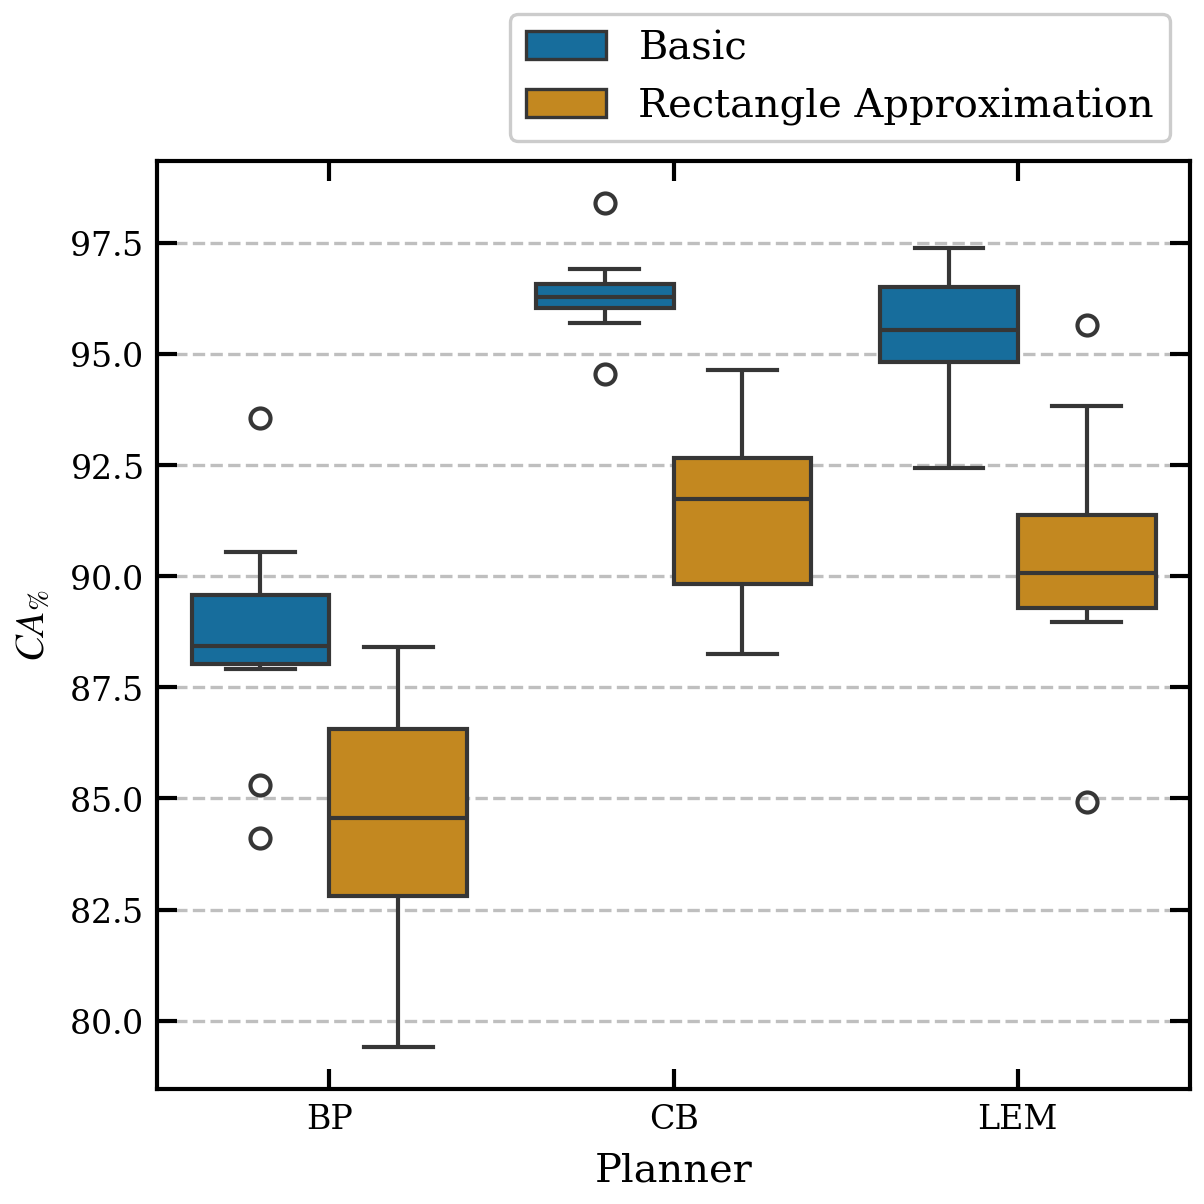

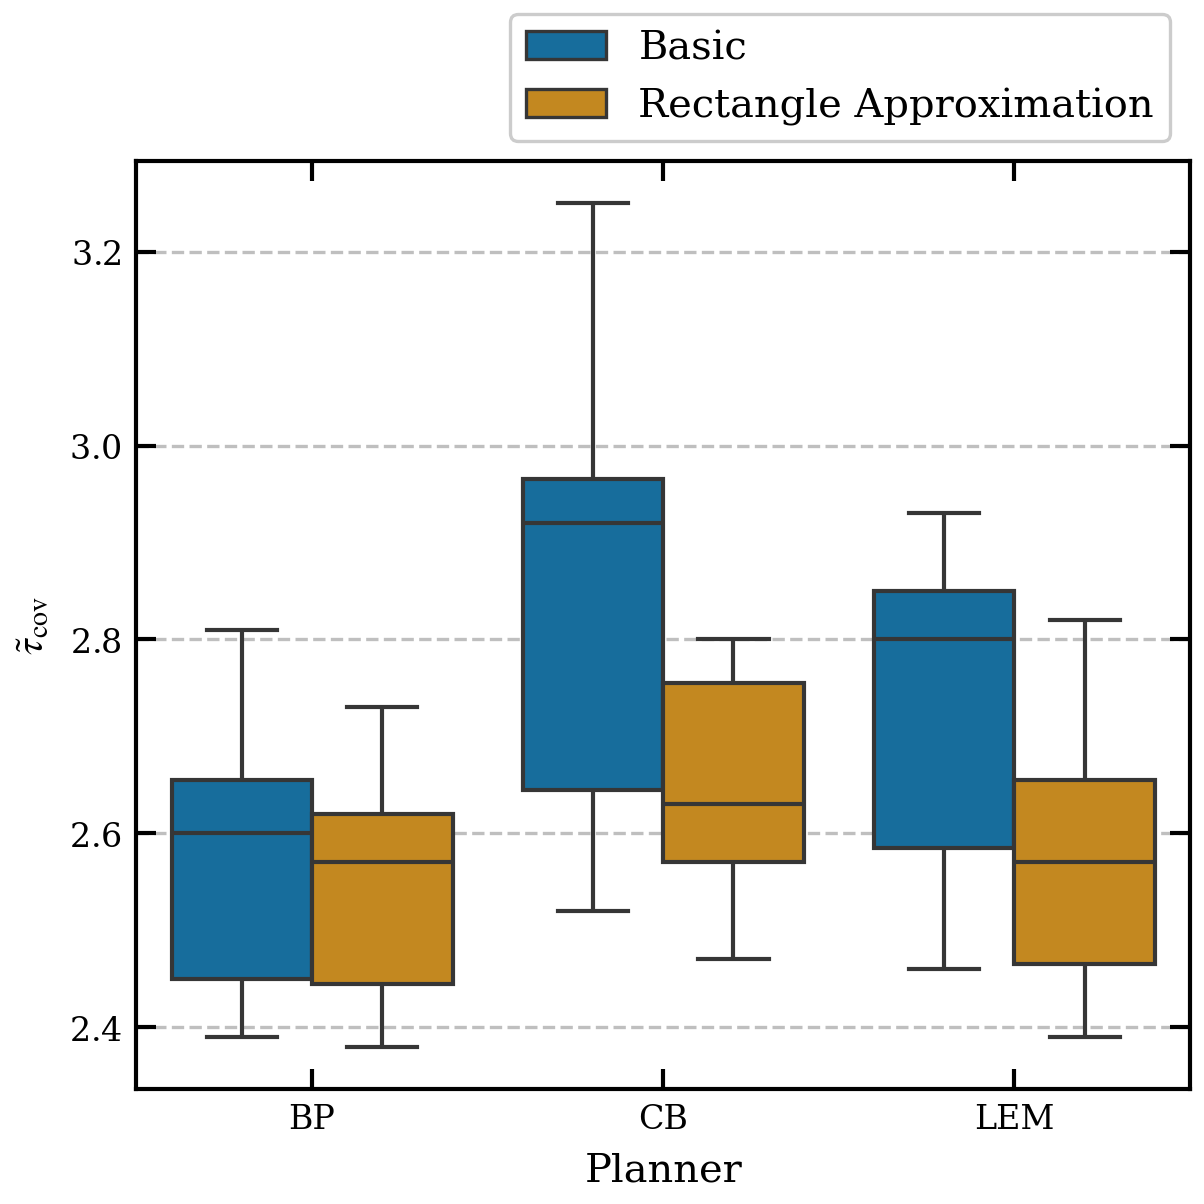

In [156]:
# Boxplots: Coverage % and Coverage Traverse Time (s) with hue=rect
plot_df_rect = df_rect_comp.copy()
plot_df_rect['planner'] = pd.Categorical(plot_df_rect['planner'], categories=planner_order, ordered=True)

# Map boolean rect to friendly labels for legend
plot_df_rect['rect_label'] = plot_df_rect['rect'].map({False: 'Basic', True: 'Rectangle Approximation'})
rect_hue_order = ['Basic', 'Rectangle Approximation']

fig_size = (4.0, 4.0)

fig, ax = plt.subplots(1, 1, figsize=fig_size, layout="constrained")
sns.boxplot(data=plot_df_rect, x='planner', y='area_coverage_pc', hue='rect_label', order=planner_order, hue_order=rect_hue_order)
ax.set_xlabel('Planner')
ax.set_ylabel('$CA_{\%}$')
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), frameon=True)
# ax.legend(loc='lower right', frameon=True)
# ax.set_title('Coverage: Basic vs Rectangle Approximation')
fig.savefig(f"p1_coverage_comparison_rect_vs_basic.{save_format}", dpi=save_dpi, format=save_format)

fig, ax = plt.subplots(1, 1, figsize=fig_size, layout="constrained")
sns.boxplot(data=plot_df_rect, x='planner', y='trav_time_coverage', hue='rect_label', order=planner_order, hue_order=rect_hue_order)
ax.set_xlabel('Planner')
ax.set_ylabel('$\\tilde{\\tau}_{\mathrm{cov}}$')
ax.legend(loc='lower right', bbox_to_anchor=(1.0, 1.0), frameon=True)
# ax.legend(loc='upper right', frameon=True)
# ax.legend(bbox_to_anchor=(1, 1.01), loc='upper left')
# ax.set_title('Coverage Path Tracking Time: Basic vs Rectangle Estimation')
# ax.set_ylim(1, 4)
fig.savefig(f"p2_coverage_time_comparison_rect_vs_basic.{save_format}", dpi=save_dpi, format=save_format)

plt.show()

## Coverage Planner Comparison (No Rect, MILP) in normalized table

This section builds a publication-ready table comparing coverage planning methods without rectangle estimation under the MILP sequencer. We filter MapT1–MapT11 results to `rect = False` (rectangle) and `sequencer = MILP`, then assemble a multi-metric table (Coverage %, Overlap %, Path Length, Smoothness, Runtime) with per-map entries and an `Average ± Std` summary row. Best values per map/metric are highlighted.


In [157]:
# Build MILP/rect comparison table across planners

# Work on a copy of the preloaded metrics_df
df_norm_e1 = df_norm.copy()

# Robust filter: rectangle and MILP sequencer
# rect column is boolean-like
rect_mask = df_norm_e1['rect'] == False
milp_mask = df_norm_e1['sequencer'] == 'milp'
df_norm_e1 = df_norm_e1[rect_mask & milp_mask].copy()

## Aggregate Plots (No Rect, MILP)

We visualize planner performance across M1–M11 (no rectangle; MILP sequence):

- Boxplots per metric to summarize distributions across maps.
- Grouped bar charts per map for key metrics.
- Trade-off scatter (Path Length/Area vs Overlap%) to reveal Pareto trends.
  Figures are saved for inclusion in the paper.


In [158]:
# Use normalized dataframe built earlier
plot_df = df_norm_e1.copy()

# Ensure consistent planner ordering
planner_order = planners_a

# Keep only relevant columns
cols_keep = ['map_name', 'planner', 'fplanner', 'area_coverage_pc', 'area_overlap_pc',
             'l_path_coverage', 'yaw_path_coverage', 'trav_time_coverage']
plot_df = plot_df[cols_keep]

# Drop rows with missing normalization (e.g., zero-length paths)
plot_df = plot_df.dropna()

# Sort maps for grouped bars
map_order = [f'M{i}' for i in range(1, 12)]
plot_df['map_name'] = pd.Categorical(plot_df['map_name'], categories=map_order, ordered=True)
plot_df = plot_df.sort_values(['map_name', 'planner'])

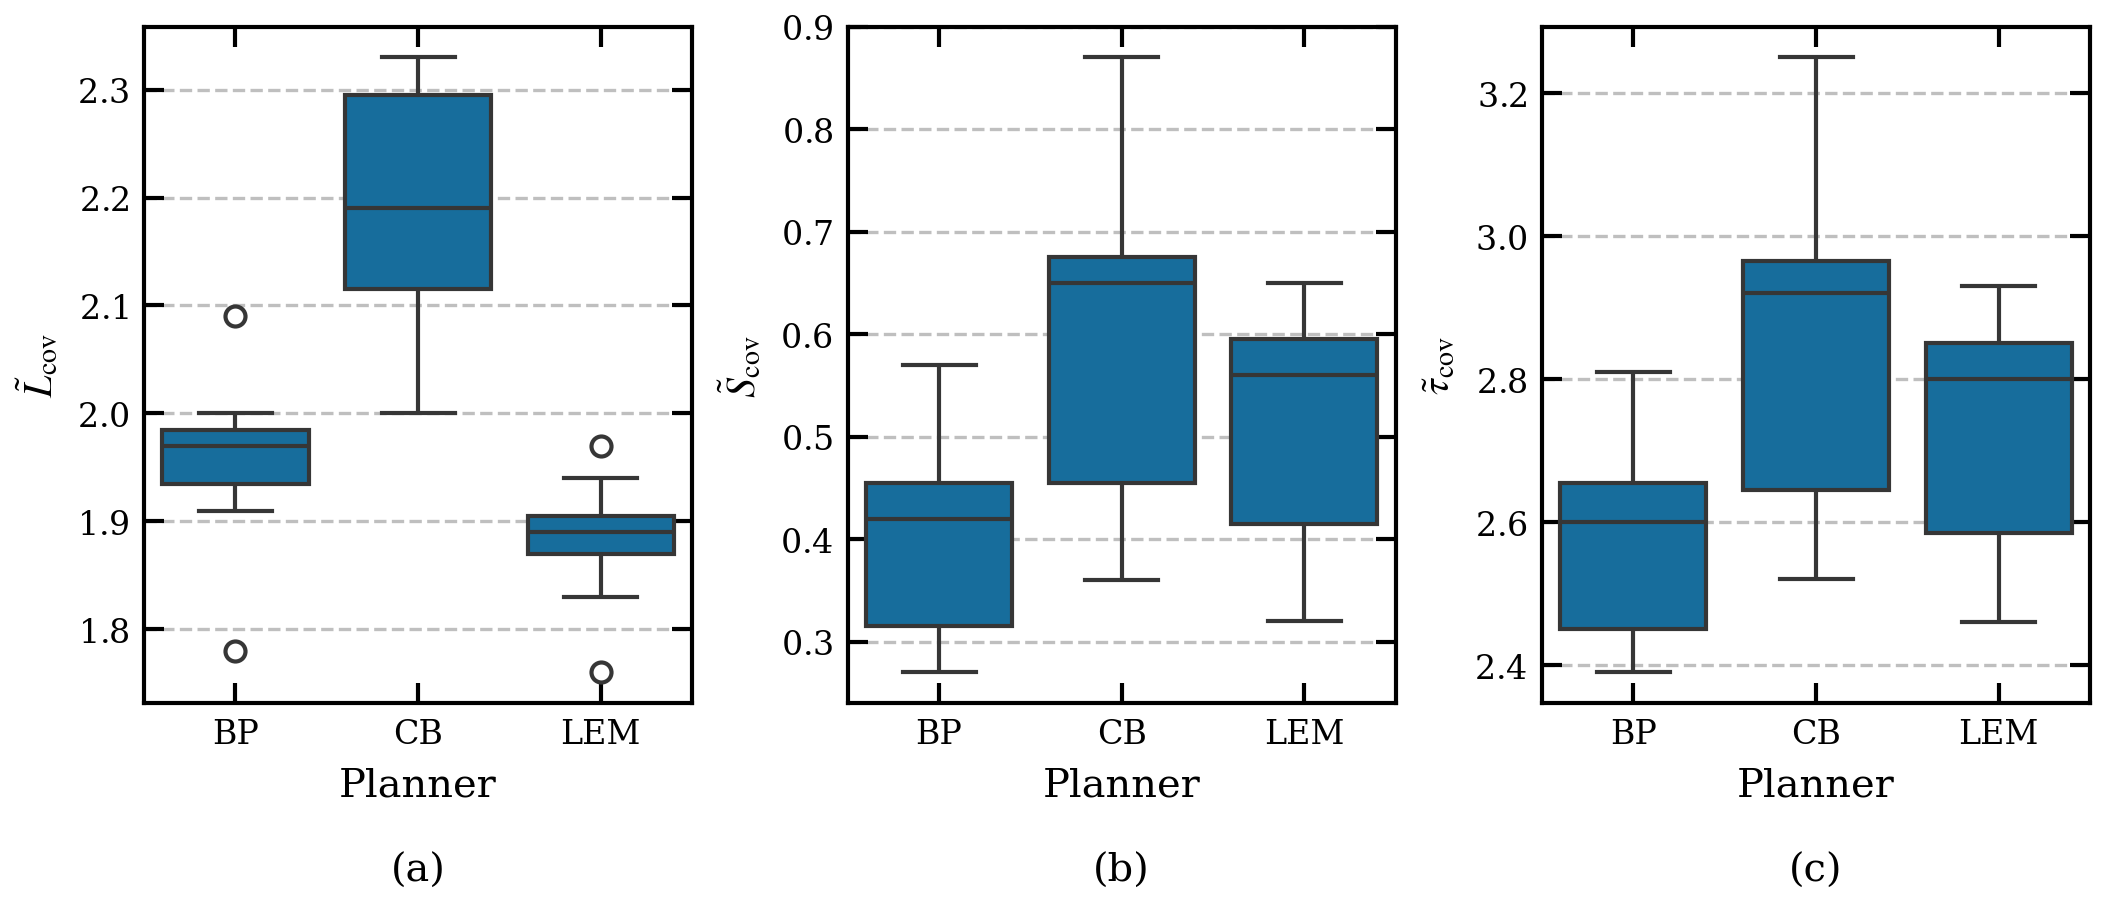

In [159]:
# Metrics to boxplot
box_metrics = [
    ('l_path_coverage', '$\\tilde{L}_{\\mathrm{cov}}$'),
    ('yaw_path_coverage', '$\\tilde{S}_{\\mathrm{cov}}$ '),
    ('trav_time_coverage', '$\\tilde{\\tau}_{\\mathrm{cov}}$')
]
fig_abc = ['a', 'b', 'c']

fig, axes = plt.subplots(1, 3, figsize=(7, 3), layout="constrained")
axes = axes.flatten()
for ax, (col, title), abc in zip(axes, box_metrics, fig_abc):
    # Ensure minor ticks are off per-axis
    ax.minorticks_off()
    sns.boxplot(data=plot_df, x='planner', y=col, order=planners_a, ax=ax)
    # ax.set_title(title)
    ax.set_xlabel(f'Planner\n\n({abc})')
    ax.set_ylabel(title)  # title.split('(')[0].strip()
    ax.tick_params(axis='x', rotation=0)

# Hide any unused subplot (in case fewer metrics)
for i in range(len(box_metrics), len(axes)):
    axes[i].axis('off')

fig.savefig(f"p4_coverage_path_boxplots.{save_format}", dpi=save_dpi, format=save_format)

plt.show()

## Coverage vs Overlap


<Figure size 3000x2400 with 0 Axes>

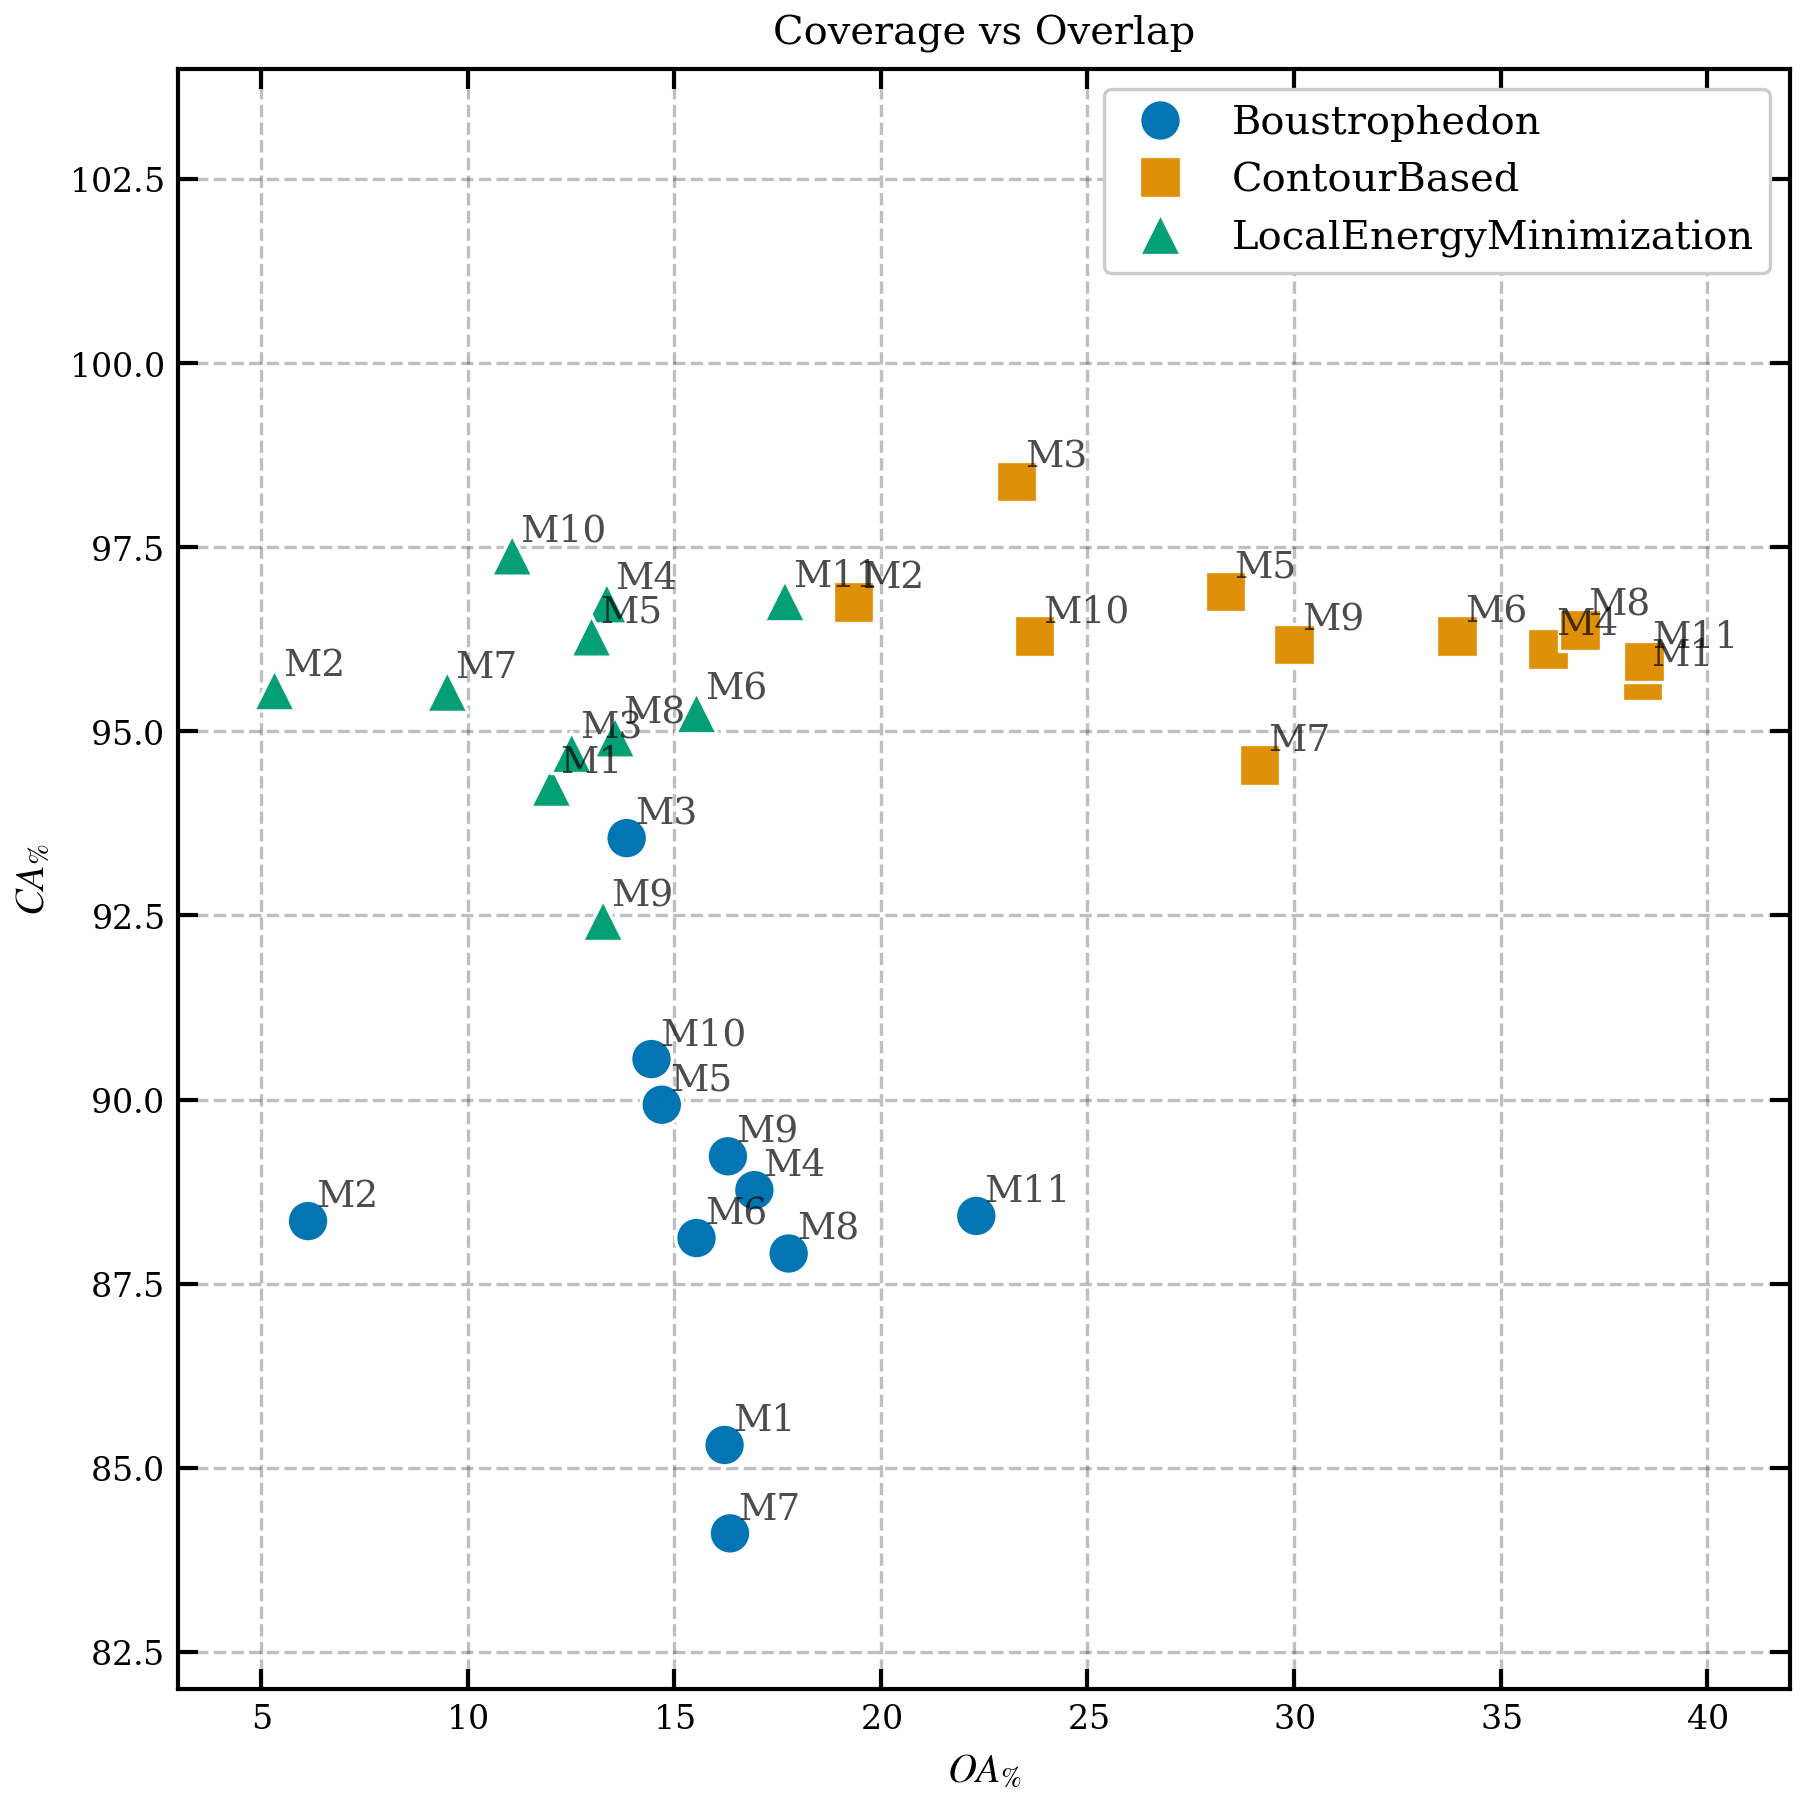

In [160]:
# Trade-off scatter: coverage pc vs overlap pc
plt.figure(figsize=(10, 8))

# Explicit marker mapping per planner for consistent styling
style_order = ['Boustrophedon', 'ContourBased', 'LocalEnergyMinimization']
markers = {
    'Boustrophedon': 'o',   # circle
    'ContourBased': 's',    # square
    'LocalEnergyMinimization': '^'  # triangle
}

fig_size = (6, 6)
fig, ax = plt.subplots(1, 1, layout="constrained", figsize=fig_size)

# Ensure minor ticks are off regardless of style
ax.minorticks_off()

sns.scatterplot(
    data=plot_df,
    x='area_overlap_pc',
    y='area_coverage_pc',
    hue='fplanner',
    style='fplanner',
    hue_order=style_order,
    style_order=style_order,
    markers=markers,
    s=100,
    alpha=0.99,
    ax=ax
)

# Annotate points with map names (optional, may clutter)
for _, r in plot_df.iterrows():
    ax.text(r['area_overlap_pc'] + 0.2, r['area_coverage_pc'] + 0.2, str(r['map_name']), fontsize=9, alpha=0.7)

ax.set_title('Coverage vs Overlap')
ax.set_xlabel('$OA_{\\%}$')
ax.set_ylabel('$CA_{\\%}$')
ax.set_xlim(3, 42)
ax.set_ylim(82, 104)
# Legend formatting
# ax.legend(loc='lower center', bbox_to_anchor=(0.5, 0.1))
ax.legend(loc='upper right', frameon=True)
# plt.legend(bbox_to_anchor=(1.0, 1), loc='upper left')
# fig.tight_layout()
plt.savefig(f"p3_scatter_coverage_vs_overlap.{save_format}", dpi=save_dpi, format=save_format)

In [161]:
# # Grouped bar charts per map for key metrics
# key_metrics = [
#     ('l_path_coverage', 'Path Length per Area (m/m^2)'),
#     ('area_overlap_pc', 'Overlap %')
# ]

# for col, title in key_metrics:
#     plt.figure(figsize=(16, 6))
#     sns.barplot(data=plot_df, x='map_name', y=col, hue='planner', hue_order=planners_a)
#     plt.title(f'{title} by Map and Method (No Rect, MILP)')
#     plt.xlabel('Map')
#     plt.ylabel(title.split('(')[0].strip())
#     plt.xticks(rotation=30)
#     plt.legend(title='Method', loc='upper right')
#     out = f'bar_{col}_no_rect_milp.png'
#     plt.tight_layout()
#     plt.savefig(out, dpi=300, bbox_inches='tight')
#     plt.show()

In [162]:
# # Trade-off scatter: Path Length per Area vs Overlap %
# # Ensure TeX is disabled for text rendering to avoid LaTeX errors
# plt.rcParams['text.usetex'] = False

# plt.figure(figsize=(10, 8))
# sns.scatterplot(data=plot_df, x='l_path_coverage', y='area_overlap_pc', hue='fplanner', style='fplanner', s=120)

# # Annotate points with map names (optional, may clutter)
# for _, r in plot_df.iterrows():
#     plt.text(r['l_path_coverage'] + 0.002, r['area_overlap_pc'] + 0.02, str(r['map_name']), fontsize=9, alpha=0.7)

# plt.title('Trade-off: Path Length per Area vs Overlap %')
# plt.xlabel('Path Length per Area (m/m²)')
# plt.ylabel('Overlap %')
# plt.legend(title='Planner')
# plt.tight_layout()
# # plt.savefig('scatter_path_per_area_vs_overlap.png', dpi=300, bbox_inches='tight')
# plt.show()

In [163]:
# # Trade-off scatter: coverage pc vs overlap pc

# # Explicit marker mapping per planner for consistent styling
# style_order = ['Boustrophedon', 'ContourBased', 'LocalEnergyMinimization']
# markers = {
#     'Boustrophedon': 'o',   # circle
#     'ContourBased': 's',    # square
#     'LocalEnergyMinimization': '^'  # triangle
# }

# # Larger figure and constrained layout for better spacing
# fig, ax = plt.subplots(1, 1, figsize=(16, 9), layout="constrained")

# sns.scatterplot(
#     data=plot_df,
#     x='area_overlap_pc',
#     y='area_coverage_pc',
#     hue='fplanner',
#     style='fplanner',
#     hue_order=style_order,
#     style_order=style_order,
#     markers=markers,
#     s=80,            # slightly smaller markers to reduce crowding
#     alpha=0.95,
#     ax=ax
# )

# # Add dynamic axis padding to increase whitespace around points
# xmin, xmax = plot_df['area_overlap_pc'].min(), plot_df['area_overlap_pc'].max()
# ymin, ymax = plot_df['area_coverage_pc'].min(), plot_df['area_coverage_pc'].max()
# xr = xmax - xmin
# yr = ymax - ymin
# xpad = 0.06 * xr if xr > 0 else 1.0
# ypad = 0.08 * yr if yr > 0 else 1.0
# # ax.set_xlim(xmin - xpad, xmax + xpad)
# # ax.set_ylim(ymin - ypad, ymax + ypad)
# # ax.margins(x=0.05, y=0.08)

# # # Offset label annotations to reduce overlap (cycled offsets)
# # # offsets = [(8, 8), (-8, 8), (8, -8), (-8, -8), (12, 0), (-12, 0)]
# # for i, (_, r) in enumerate(plot_df.iterrows()):
# #     dx, dy = offsets[i % len(offsets)]
# #     ax.annotate(
# #         str(r['map_name']),
# #         (r['area_overlap_pc'], r['area_coverage_pc']),
# #         xytext=(dx, dy), textcoords='offset points',
# #         fontsize=9, alpha=0.8
# #     )

# ax.set_title('Coverage vs Overlap')
# ax.set_xlabel('$OA_{\\%}$')
# ax.set_ylabel('$CA_{\\%}$')
# # Legend formatting
# ax.legend(loc='lower center', bbox_to_anchor=(0.5, 0.05))
# # fig.tight_layout()
# # plt.savefig('scatter_coverage_vs_overlap.png', dpi=300)  # , bbox_inches='tight'
# plt.show()

In [164]:
# # Select metrics (coverage-only effects)
# metrics = [
#     ('area_coverage_pc', 'Coverage %'),
#     ('area_overlap_pc', 'Overlap %'),
#     ('l_path_coverage', 'Path Length'),
#     ('yaw_path_coverage', 'Smoothness'),
#     ('trav_time_coverage', 'Time per m'),
#     ('pt_coverage_planning', 'Runtime (s)'),
# ]

# # Pivot per metric and concatenate into a MultiIndex column table
# pivot_tables = []
# for col, label in metrics:
#     pv = df_norm_e1.pivot(index='map_name', columns='planner', values=col)
#     # Reindex columns to desired order if present
#     existing = [m for m in planners_a if m in pv.columns]
#     pv = pv.reindex(columns=existing)
#     pivot_tables.append(pv)

# table_1 = pd.concat(pivot_tables, axis=1, keys=[lbl for _, lbl in metrics])
# table_1 = table_1.sort_index()
# # sort rows by map_name Map1 to Map11
# map_order = [f'M{i}' for i in range(1, 12)]
# table_1 = table_1.reindex(map_order)
# table_1

In [165]:
# # Add Average ± Std row (per metric/planner)
# avg = table_1.mean(axis=0, skipna=True)
# std = table_1.std(axis=0, ddof=1, skipna=True)
# avg_std = (avg.round(2).astype(str) + ' ± ' + std.round(2).astype(str)).to_frame().T
# avg_std.index = ['Average ± Std']
# table_1_stats = pd.concat([table_1, avg_std], axis=0)

# # Styling: format numbers and bold best per-map values per metric


# def highlight_best(row):
#     styles = [''] * len(row)
#     if row.name == 'Average ± Std':
#         return styles
#     # Per metric (level 0), bold the best value among planners (level 1)
#     level0 = table_1_stats.columns.get_level_values(0)
#     unique_metrics = list(dict.fromkeys(level0))
#     for metric_label in unique_metrics:
#         idxs = [i for i, l in enumerate(level0) if l == metric_label]
#         vals = pd.to_numeric(row.iloc[idxs], errors='coerce')
#         if vals.notna().any():
#             # For Coverage %, higher is better; for others, lower is better
#             if metric_label == 'Coverage %':
#                 best_val = vals.max()
#             else:
#                 best_val = vals.min()
#             for i in idxs:
#                 if pd.to_numeric(row.iloc[i], errors='coerce') == best_val:
#                     styles[i] = 'font-weight: bold'
#     return styles


# # Format all numeric entries to 2 decimals
# fmt = {}
# for metric_label in table_1_stats.columns.get_level_values(0).unique():
#     for planner_label in table_1_stats.columns.get_level_values(1).unique():
#         # Only format numeric columns (exclude the Average ± Std row which is strings)
#         fmt[(metric_label, planner_label)] = lambda x: f'{x:.1f}' if isinstance(x, (int, float)) else x

# table_1_stats.style.apply(highlight_best, axis=1).format(fmt)

# SDF vs MILP sequence optimization

compare normalized connection paths between two sequence optimization methods

(consider only rect=True cases)

compare: normalized connection paths

copare: sequence planning process time


In [166]:
# Build table 2: MILP vs SDF sequencers comparison
# Work on a copy of the preloaded metrics_df
df_norm_e2 = df_norm.copy()
# Robust filter: rectangle and MILP or SDF sequencer
rect_mask = df_norm_e2['rect'] == True
df_norm_e2 = df_norm_e2[rect_mask].copy()

# columns to keep
cols_keep = ['map_name', 'planner', 'fplanner', 'sequencer',
             'l_path_connect', 'trav_time_connect', 'pt_sequencing']
df_norm_e2 = df_norm_e2[cols_keep]

df_norm_e2.head(10)

,map_name,planner,fplanner,sequencer,l_path_connect,trav_time_connect,pt_sequencing
1,M11,CB,ContourBased,milp,0.27,3.77,32.87
2,M11,BP,Boustrophedon,milp,0.33,3.39,35.47
3,M11,BP,Boustrophedon,dfs,0.51,3.03,2.91
5,M11,LEM,LocalEnergyMinimization,dfs,0.45,2.83,3.40
6,M11,LEM,LocalEnergyMinimization,milp,0.26,3.49,32.09
7,M11,CB,ContourBased,dfs,0.49,3.03,3.17
10,M5,CB,ContourBased,milp,0.26,4.01,17.45
11,M5,BP,Boustrophedon,milp,0.29,3.58,20.46
12,M5,BP,Boustrophedon,dfs,0.42,3.44,2.00
14,M5,LEM,LocalEnergyMinimization,dfs,0.36,3.74,1.88


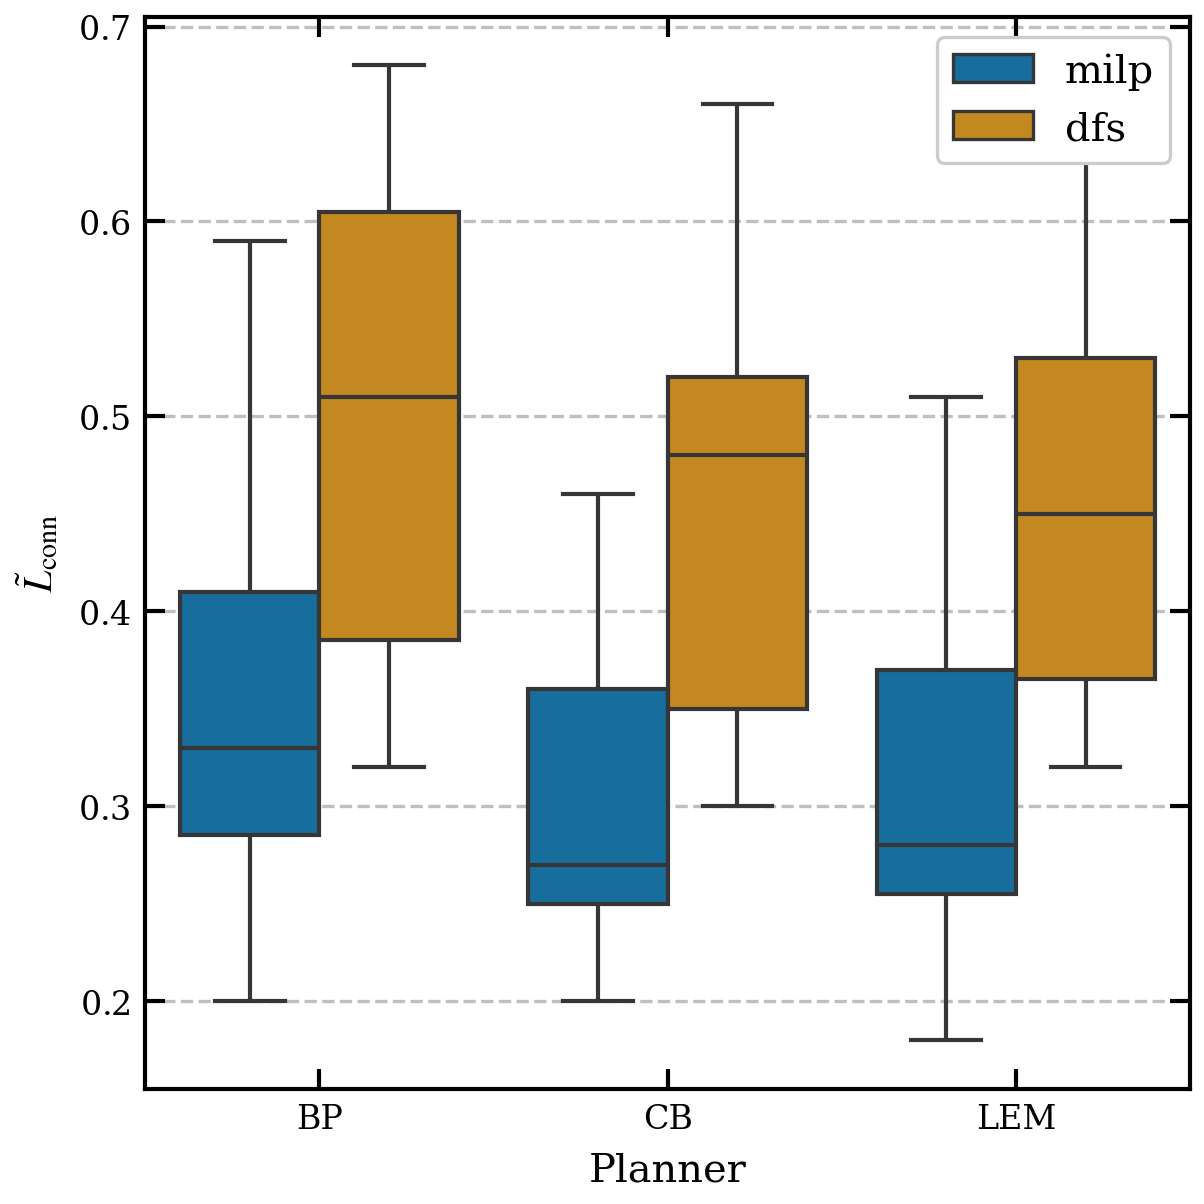

In [167]:
# Select metrics (coverage-only effects)
metrics = [
    ('l_path_connect', 'Connection Path Length'),
    ('trav_time_connect', 'Connection Time per m'),
    ('pt_sequencing', 'Sequencing Runtime (s)'),
]

# box plots: MILP vs DFS sequencers comparison normalized connection path length
plot_df_seq = df_norm_e2.copy()
plot_df_seq['planner'] = pd.Categorical(plot_df_seq['planner'], categories=planner_order, ordered=True)
fig_size = (4.0, 4.0)
fig, ax = plt.subplots(1, 1, figsize=fig_size, layout="constrained")
sns.boxplot(data=plot_df_seq, x='planner', y='l_path_connect', hue='sequencer', order=planner_order)
ax.set_xlabel('Planner')
ax.set_ylabel('$\\tilde{L}_{\mathrm{conn}}$')
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=True)
fig.savefig(f"p5_milp_vs_dfs_connection_path.{save_format}", dpi=save_dpi, format=save_format)
# plt.show()

In [168]:
# # for results with same (map_name, planner, fplanner), show l_path_connect comparison between milp and dfs sequencers
# df_seq_comp = df_norm_e2.pivot_table(index=['map_name', 'planner', 'fplanner'],
#                                      columns='sequencer',
#                                      values='l_path_connect').reset_index()
# df_seq_comp = df_seq_comp.dropna().copy()
# df_seq_comp['l_path_connect_diff'] = df_seq_comp['dfs'] - df_seq_comp['milp']
# # convert to difference percentage
# df_seq_comp['l_path_connect_diff_pc'] = (df_seq_comp['l_path_connect_diff'] / df_seq_comp['milp']) * 100
# # round to 2 decimals
# df_seq_comp['l_path_connect_diff_pc'] = df_seq_comp['l_path_connect_diff_pc'].round(2)
# # df_seq_comp

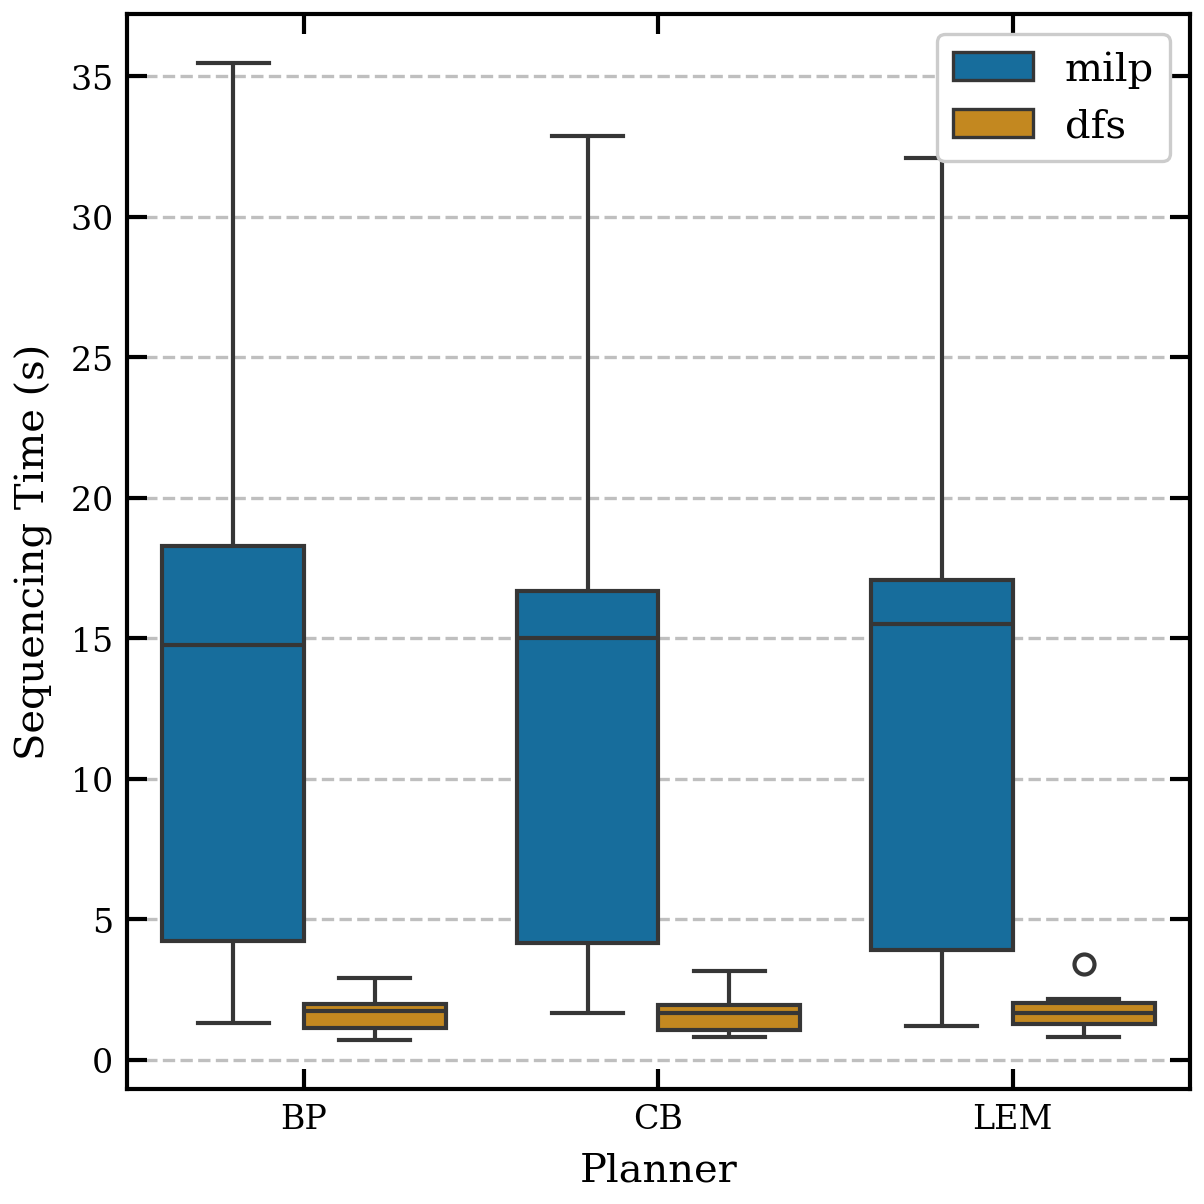

In [169]:
# box plots: MILP vs DFS sequencers comparison, processing time
fig_size = (4.0, 4.0)
fig, ax = plt.subplots(1, 1, figsize=fig_size, layout="constrained")
sns.boxplot(data=plot_df_seq, x='planner', y='pt_sequencing', hue='sequencer', order=planner_order)
ax.set_xlabel('Planner')
ax.set_ylabel('Sequencing Time (s)')
ax.legend(loc='upper right', bbox_to_anchor=(1.0, 1.0), frameon=True)
fig.savefig(f"p6_milp_vs_dfs_sequencing_time.{save_format}", dpi=save_dpi, format=save_format)
plt.show()

In [171]:
# Select metrics
metrics = [
    ('l_path_connect', 'Connection Path Length'),
    ('trav_time_connect', 'Connection Time per m'),
    ('pt_sequencing', 'Sequencing Runtime (s)'),
]

# Pivot per metric and concatenate into a MultiIndex column table
pivot_tables = []
for col, label in metrics:
    # use pivot_table with aggregation to handle duplicate map_name entries safely
    pv = df_norm_e2.pivot_table(index='map_name', columns='sequencer', values=col, aggfunc='mean')
    # Reindex columns to desired order if present
    existing = [m for m in ['milp', 'dfs'] if m in pv.columns]
    pv = pv.reindex(columns=existing)
    pivot_tables.append(pv)

table_2 = pd.concat(pivot_tables, axis=1, keys=[lbl for _, lbl in metrics])
table_2 = table_2.sort_index()
# sort rows by map_name Map1 to Map11
map_order = [f'M{i}' for i in range(1, 12)]
table_2 = table_2.reindex(map_order)
# table_2

# Add Average ± Std row (per metric/planner) df_norm_e2
avg = table_2.mean(axis=0, skipna=True)
std = table_2.std(axis=0, ddof=1, skipna=True)
avg_std = (avg.round(2).astype(str) + ' ± ' + std.round(2).astype(str)).to_frame().T
avg_std.index = ['Average ± Std']
table_2 = pd.concat([table_2, avg_std], axis=0)
table_2

Connection Path Length              Connection Time per m  \
sequencer                       milp          dfs                  milp   
M1                              0.52         0.67              4.313333   
M2                          0.193333     0.346667              3.893333   
M3                          0.266667          0.4              4.146667   
M4                          0.236667     0.323333                  3.33   
M5                          0.266667     0.373333              3.876667   
M6                              0.36         0.55              4.243333   
M7                          0.393333     0.553333              3.906667   
M8                              0.36         0.52                  4.13   
M9                          0.416667     0.623333                  4.01   
M10                         0.273333     0.353333              3.516667   
M11                         0.286667     0.483333                  3.55   
Average ± Std            0.32 ± 0.09  0.47 ± 0.12            3.9 ± 0.32   

                           Sequencing Runtime (s)               
sequencer              dfs                   milp          dfs  
M1                    3.89               2.366667     0.923333  
M2                3.313333                   1.38     0.793333  
M3                3.723333               2.133333     0.793333  
M4                3.246667              15.843333     2.353333  
M5                3.656667                  18.46     1.903333  
M6                    3.56              22.456667     1.986667  
M7                    3.59                  15.38     1.926667  
M8                    3.78              13.006667         1.65  
M9                3.503333              15.536667     1.626667  
M10                   3.21                    5.8     1.383333  
M11               2.963333              33.476667         3.16  
Average ± Std  3.49 ± 0.28           13.26 ± 9.88  1.68 ± 0.71